# Shanghai–Hong Kong Market Linkages: Prediction, Identification and Cointegration

This coursework-based study examines Shanghai and Hong Kong return linkages using 2,599 paired price observations and a fixed-origin 20-observation holdout. A VAR(7) provides a small Shanghai RMSE improvement over zero returns but performs worse for Hong Kong; neither Granger direction is significant at five percent. Reversing the Cholesky ordering changes Shanghai's contribution to Hong Kong's ten-step forecast-error variance from 32.428152% to 0.350971%, demonstrating identification sensitivity. A separate 1,461-observation system of logged equity prices, SHIBOR, and exchange rates selects Johansen rank two across three difference-lag specifications, while all fitted VECMs reject residual whiteness. The evidence separates prediction, contemporaneous shock identification, and conditional cointegration results, without establishing structural causality or a robust long-run equilibrium.

## Data audit and evaluation design

VARSJ contains 2,599 paired index prices. SZH denotes Shanghai Composite and XGH Hang Seng according to the supplied course. Returns are 100 times first differences of natural logs. The final 20 common observations are a fixed-origin holdout, leaving 2,578 training returns. No interpolation or synthetic trading dates are introduced. XZSJ is a separate 1,461-row in-sample system: SZH is already logged, SHIBOR is the course's seven-day rate, and EX is yuan per US dollar. The datasets are not merged.

In [1]:
%matplotlib inline
import json
import warnings
warnings.formatwarning = lambda message, category, filename, lineno, line=None: (
    f"{category.__name__}: {message}\n")
from pathlib import Path
from inspect import signature
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import select_coint_rank, coint_johansen, VECM
from numpy.exceptions import ComplexWarning
from IPython.display import display, Markdown
if "result_object" in signature(adfuller).parameters:
    adfuller = partial(adfuller, result_object=False)
DATA_DIR = Path(".")
output = Path("results")
output.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv(DATA_DIR / "VARSJ.csv", encoding="gbk")
prices = raw[["SZH", "XGH"]].apply(pd.to_numeric)
prices.index = pd.to_datetime(raw.iloc[:, 0])
prices.index.name = "Date"
prices = prices.sort_index()

levels = pd.read_csv(DATA_DIR / "XZSJ.csv", parse_dates=["Time"])
levels = levels.set_index("Time")[["SZH", "SHIBOR", "EX"]].apply(pd.to_numeric).sort_index()
levels.index.name = "Date"
for name, frame in (("Prices", prices), ("Levels", levels)):
    if frame.index.hasnans or frame.index.has_duplicates:
        raise ValueError(f"{name}: dates must be valid and unique.")
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError(f"{name}: all observations must be finite.")
if (prices <= 0).any().any():
    raise ValueError("Prices must be positive before taking logarithms.")

log_prices = np.log(prices)
returns = 100 * log_prices.diff().dropna()
H = 20
train, test = returns.iloc[:-H].copy(), returns.iloc[-H:].copy()
if len(train) < 500:
    raise ValueError("At least 500 training returns are required.")

sample_rows = []
for name, frame in (("Prices", prices), ("VAR training", train),
                    ("VAR holdout", test), ("Cointegration levels", levels)):
    sample_rows.append({"Dataset": name, "Rows": len(frame),
                        "Start": str(frame.index[0].date()), "End": str(frame.index[-1].date())})
display(pd.DataFrame(sample_rows).set_index("Dataset"))
display(prices.head(3))
assert (len(prices), len(train), len(test), len(levels)) == (2599, 2578, 20, 1461)
assert train.index[-1] < test.index[0]
assert not train.index.intersection(test.index).size

,Rows,Start,End
Dataset,,,
Prices,2599,2011-01-04,2021-12-31
VAR training,2578,2011-01-05,2021-12-02
VAR holdout,20,2021-12-03,2021-12-31
Cointegration levels,1461,2016-01-04,2021-12-31


,SZH,XGH
Date,,
2011-01-04,2852.648,23668.48
2011-01-05,2838.593,23757.82
2011-01-06,2824.197,23786.30


## Training history and stationarity

Constant-only ADF regressions use maxlag=12 and AIC augmentation selection. Shanghai log prices fail to reject a unit root (p=0.405073), while returns reject (p approximately 1.06e-29). These are specification-dependent tests, not proof of independence or normality.

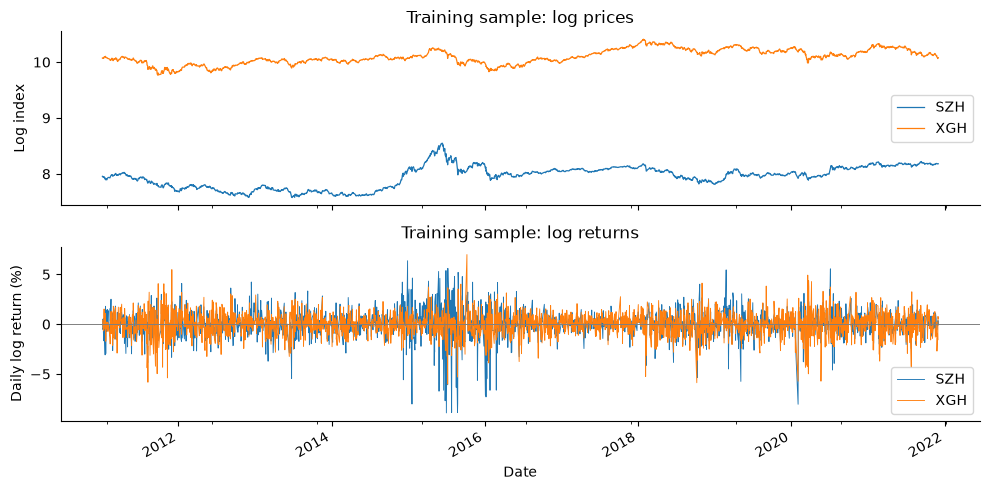

Deterministic        ADF       p_value  Lags  N_obs
Transform  Series                                                    
Log price  SZH                c  -1.750947  4.050726e-01     8   2570
           XGH                c  -2.328916  1.628116e-01     0   2578
Log return SZH                c -16.881677  1.061711e-29     7   2570
           XGH                c -50.885678  0.000000e+00     0   2577

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
log_prices.loc[:train.index[-1]].plot(ax=axes[0], lw=0.9)
axes[0].set(title="Training sample: log prices", ylabel="Log index")
train.plot(ax=axes[1], lw=0.65)
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].set(title="Training sample: log returns", ylabel="Daily log return (%)", xlabel="Date")
fig.tight_layout()
fig.savefig(output / "training_history.png", dpi=170)
plt.show()
def adf_table(frame, regression="c", maxlag=12):
    rows = []
    for name in frame.columns:
        result = adfuller(frame[name].dropna(), regression=regression,
                          maxlag=maxlag, autolag="AIC")
        rows.append({"Series": name, "Deterministic": regression,
                     "ADF": result[0], "p_value": result[1],
                     "Lags": result[2], "N_obs": result[3]})
    return pd.DataFrame(rows).set_index("Series")

z_train = log_prices.loc[:train.index[-1]]
adf_prices = adf_table(z_train)
adf_returns = adf_table(train)
display(pd.concat({"Log price": adf_prices, "Log return": adf_returns},
                  names=["Transform", "Series"]))
pd.concat({"Log price": adf_prices, "Log return": adf_returns}).to_csv(
    output / "return_system_adf.csv")

## VAR specification and residual diagnostics

The training-only select_order(12) comparison selects seven lags by AIC/FPE and zero by BIC/HQIC. VAR(7) is retained as the course's AIC-based specification. Information criteria use a common truncated sample; residual tests use each model's available training sample. VAR(0) is constant-only. Portmanteau horizons are 12, except 24 for VAR(12). The VAR(7) is stable and its whiteness p-value is 0.770917; this does not establish constant variance, Gaussian errors or absence of structural breaks.

In [3]:
model = VAR(train.reset_index(drop=True))
selection = model.select_order(maxlags=12)
ic_table = pd.DataFrame(selection.ics).rename_axis("Lag")
display(ic_table)
print("Selected lags:", {name: int(value) for name, value in selection.selected_orders.items()})


fits = {p: model.fit(p, trend="c") for p in (1, 7)}
diagnostics = []
for p, fit in fits.items():
    white = fit.test_whiteness(nlags=12)
    diagnostics.append({"Lag": p, "AIC_common": ic_table.loc[p, "aic"],
                        "BIC_common": ic_table.loc[p, "bic"],
                        "Stable": fit.is_stable(), "White_p": white.pvalue})
display(pd.DataFrame(diagnostics).set_index("Lag"))

fit_var = fits[7]
display(fit_var.params.head(5))
lag_rows = []
for p in range(13):
    candidate = VAR(train.reset_index(drop=True)).fit(p, trend='c')
    lag_rows.append({'Lag': p, 'AIC_common': float(ic_table.loc[p, 'aic']), 'BIC_common': float(ic_table.loc[p, 'bic']), 'Stable': bool(candidate.is_stable()) if p else True, 'White12_p': float(candidate.test_whiteness(nlags=12 if p < 12 else 24).pvalue), 'White_test_horizon': 12 if p < 12 else 24})
lag_diagnostics = pd.DataFrame(lag_rows)
display(lag_diagnostics)
fit_var.params.to_csv(output / "var_parameters.csv")

,aic,bic,hqic,fpe
Lag,,,,
0,0.574031,0.578590,0.575684,1.775409
1,0.571024,0.584703,0.575983,1.770078
2,0.570242,0.593041,0.578508,1.768695
3,0.571113,0.603031,0.582686,1.770237
4,0.570599,0.611636,0.585478,1.769326
5,0.569072,0.619229,0.587258,1.766628
6,0.565828,0.625104,0.587320,1.760906
7,0.564085,0.632481,0.588883,1.757840
8,0.565158,0.642673,0.593263,1.759727


Selected lags: {'aic': 7, 'bic': 0, 'hqic': 0, 'fpe': 7}


,AIC_common,BIC_common,Stable,White_p
Lag,,,,
1,0.571024,0.584703,True,0.000107
7,0.564085,0.632481,True,0.770917


,SZH,XGH
const,0.009023,-0.000385
L1.SZH,0.034981,-0.042808
L1.XGH,0.005394,0.023765
L2.SZH,-0.059291,-0.033386
L2.XGH,0.068328,0.030723


,Lag,AIC_common,BIC_common,Stable,White12_p,White_test_horizon
0,0,0.574031,0.578590,True,0.000015,12
1,1,0.571024,0.584703,True,0.000107,12
2,2,0.570242,0.593041,True,0.002126,12
3,3,0.571113,0.603031,True,0.001882,12
4,4,0.570599,0.611636,True,0.006458,12
5,5,0.569072,0.619229,True,0.033103,12
6,6,0.565828,0.625104,True,0.251623,12
7,7,0.564085,0.632481,True,0.770917,12
8,8,0.565158,0.642673,True,0.783972,12
9,9,0.567070,0.653705,True,0.751239,12


## Fixed-origin forecast evaluation

The last seven training observations initialize a single 20-step forecast. No actual holdout return is fed back into the model. Forecasts for 2021-12-03 are 0.10606119% (SZH) and 0.03782405% (XGH). VAR RMSE is slightly lower than zero returns for Shanghai and higher for Hong Kong; MAE is higher for both. This mixed performance does not establish broad predictive superiority.

MAE      RMSE
Model       Series                    
VAR(7)      SZH     0.644862  0.719840
            XGH     0.857044  1.111089
Zero return SZH     0.643534  0.721135
            XGH     0.853392  1.103932

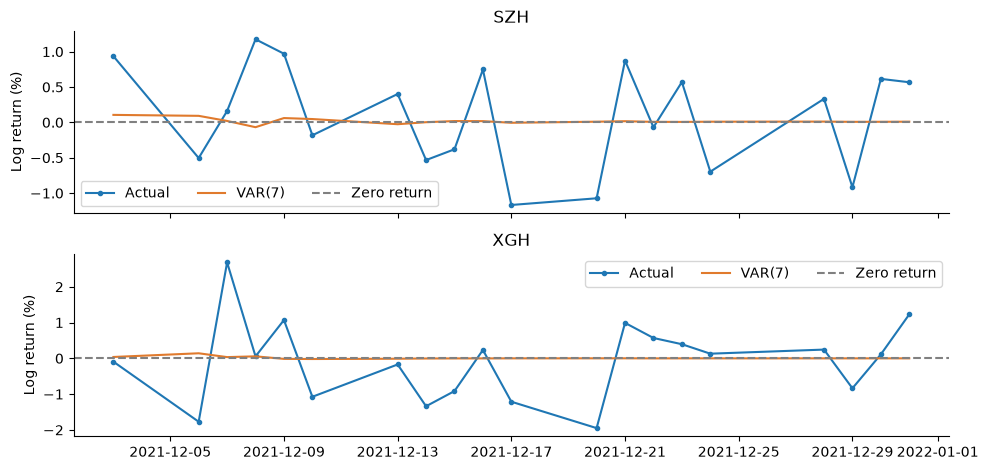

,SZH,XGH
Date,,
2021-12-03,0.106061,0.037824


In [4]:
last_p = train.to_numpy()[-fit_var.k_ar:]
forecast = pd.DataFrame(fit_var.forecast(last_p, steps=H),
                        index=test.index, columns=test.columns)
metrics = []
for label, prediction in (("VAR(7)", forecast),
                          ("Zero return", pd.DataFrame(0.0, index=test.index, columns=test.columns))):
    errors = prediction - test
    for name in test.columns:
        metrics.append({"Model": label, "Series": name,
                        "MAE": errors[name].abs().mean(),
                        "RMSE": np.sqrt(errors[name].pow(2).mean())})
forecast_metrics = pd.DataFrame(metrics).set_index(["Model", "Series"])
display(forecast_metrics)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
for ax, name in zip(axes, test.columns):
    ax.plot(test.index, test[name], "o-", ms=3, label="Actual")
    ax.plot(forecast.index, forecast[name], color="#E07A2D", label="VAR(7)")
    ax.axhline(0, color="gray", ls="--", label="Zero return")
    ax.set(title=name, ylabel="Log return (%)")
    ax.legend(loc="best", ncol=3)
fig.tight_layout()
fig.savefig(output / "holdout_forecasts.png", dpi=170)
plt.show()
display(forecast.head(1))
assert forecast.index.equals(test.index) and forecast.shape == (20, 2)
assert np.isfinite(forecast.to_numpy()).all()
evaluation = test.add_prefix("actual_").join(forecast.add_prefix("forecast_"))
evaluation["zero_SZH"] = 0.0
evaluation["zero_XGH"] = 0.0

## Granger predictability and impulse responses

The system F tests jointly restrict all seven lags of the other market in each return equation. Neither direction rejects at 5% (SZH to XGH p=0.257915; reverse p=0.060880). Nonrejection is not proof of no linkage. Orthogonal impulse responses use the [SZH, XGH] ordering with asymptotic pointwise 95% bands, not simultaneous path bands. Granger prediction and Cholesky shocks do not identify intervention effects.

,VAR_lag,F,p_value,Reject_5pct
Direction,,,,
SZH -> XGH,7,1.275823,0.257915,False
XGH -> SZH,7,1.929786,0.060880,False


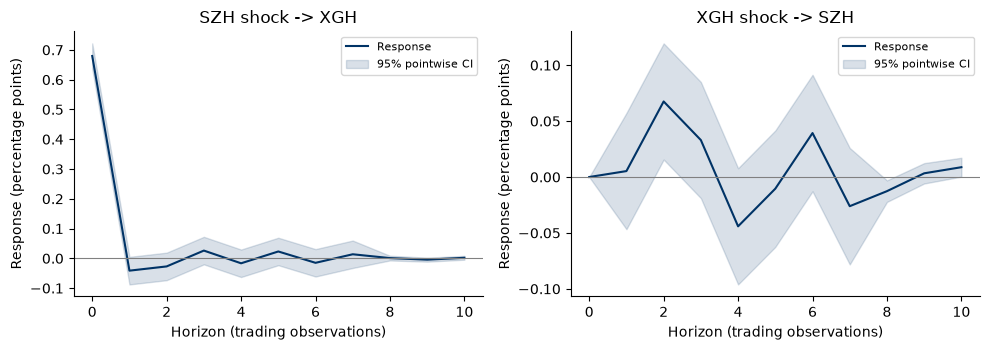

In [5]:
granger_rows = []
for cause, response in (("SZH", "XGH"), ("XGH", "SZH")):
    result = fit_var.test_causality(caused=response, causing=[cause], kind="f")
    granger_rows.append({"Direction": f"{cause} -> {response}",
                         "VAR_lag": fit_var.k_ar, "F": result.test_statistic,
                         "p_value": result.pvalue, "Reject_5pct": result.pvalue < 0.05})
display(pd.DataFrame(granger_rows).set_index("Direction"))
irf = fit_var.irf(periods=10)
orth = irf.orth_irfs
se = irf.stderr(orth=True)
horizons = np.arange(11)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (response, shock) in zip(axes, ((1, 0), (0, 1))):
    values = orth[:, response, shock]
    error = 1.96 * se[:, response, shock]
    ax.plot(horizons, values, color="#003366", label="Response")
    ax.fill_between(horizons, values - error, values + error,
                    color="#003366", alpha=0.15, label="95% pointwise CI")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(title=f"{fit_var.names[shock]} shock -> {fit_var.names[response]}",
           xlabel="Horizon (trading observations)", ylabel="Response (percentage points)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(output / "impulse_responses.png", dpi=170)
plt.show()

## Identification sensitivity

Responses and shocks are remapped by name after reversing variable order. The Shanghai contribution to Hong Kong's ten-step forecast-error variance moves from 32.428152% to 0.350971%. This change reflects different contemporaneous zero restrictions on the same sample. It is not an economic change in market transmission or a share of observed returns.

,Order,Response,Shock,Horizon,Share_pct
0,"SZH, XGH",XGH,SZH,1,32.288951
1,"SZH, XGH",XGH,SZH,5,32.407051
2,"SZH, XGH",XGH,SZH,10,32.428152
3,"SZH, XGH",SZH,XGH,1,0.000000
4,"SZH, XGH",SZH,XGH,5,0.420696
5,"SZH, XGH",SZH,XGH,10,0.553517
6,"XGH, SZH",XGH,SZH,1,0.000000
7,"XGH, SZH",XGH,SZH,5,0.296814
8,"XGH, SZH",XGH,SZH,10,0.350971
9,"XGH, SZH",SZH,XGH,1,32.288951


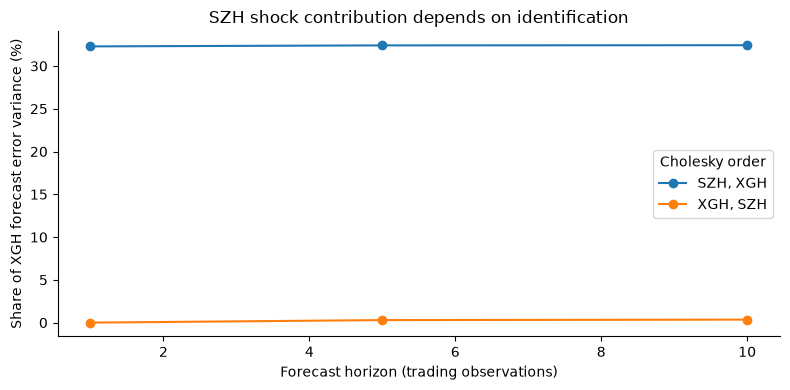

In [6]:
order_rows = []
for order in (['SZH', 'XGH'], ['XGH', 'SZH']):
    ordered_fit = VAR(train[order].reset_index(drop=True)).fit(7, trend='c')
    decomposition = ordered_fit.fevd(10).decomp
    assert np.allclose(decomposition.sum(axis=2), 1.0)
    for response, shock in (('XGH', 'SZH'), ('SZH', 'XGH')):
        for horizon in (1, 5, 10):
            order_rows.append({'Order': ', '.join(order), 'Response': response, 'Shock': shock, 'Horizon': horizon, 'Share_pct': float(decomposition[order.index(response), horizon - 1, order.index(shock)] * 100)})
order_sensitivity = pd.DataFrame(order_rows)
display(order_sensitivity)
fig, ax = plt.subplots(figsize=(8, 4))
for order_label, group in order_sensitivity.query("Response == 'XGH' and Shock == 'SZH'").groupby('Order'):
    ax.plot(group.Horizon, group.Share_pct, 'o-', label=order_label)
ax.set(xlabel='Forecast horizon (trading observations)', ylabel='Share of XGH forecast error variance (%)', title='SZH shock contribution depends on identification')
ax.legend(title='Cholesky order')
fig.tight_layout()
fig.savefig(output / 'fevd_order_sensitivity.png', dpi=180)
plt.show()

## Cointegration and specification sensitivity

The separate XZSJ system retains the supplied variable scales. Constant-only ADF tests (maxlag=11, AIC autolag) fail to reject a unit root in all levels and reject in all first differences. This is consistent with I(1), without proving integration order. The bivariate Engle–Granger test differs in variable coverage from the trivariate Johansen test. Johansen uses det_order=0 and the 5% trace rule; q counts difference lags and corresponds to a levels VAR order of q+1. The fitted VECMs retain the course's outside constant (co), which is not an interchangeable encoding of the rank-test deterministic setting.

In [7]:
display(pd.concat({
    "Level": adf_table(levels, maxlag=11),
    "First difference": adf_table(levels.diff().dropna(), maxlag=11),
}, names=["Transform", "Series"]))

eg_stat, eg_p, eg_critical = coint(
    levels["SZH"], levels["SHIBOR"], trend="c",
    maxlag=11, autolag="AIC", return_results=False
)
display(pd.DataFrame([{"Pair": "SZH, SHIBOR", "Statistic": eg_stat,
                       "p_value": eg_p, "Critical_5pct": eg_critical[1]}]))
def johansen_rank(frame, k_ar_diff):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Casting complex values to real discards the imaginary part', category=ComplexWarning, module='statsmodels\\.tsa\\.vector_ar\\.vecm')
        eigenvalues = coint_johansen(frame, det_order=0, k_ar_diff=k_ar_diff).eig
        if not np.isfinite(eigenvalues).all() or np.iscomplexobj(np.real_if_close(eigenvalues)):
            raise ValueError('Johansen eigenvalues must be finite and real. Check the data and lags.')
        return select_coint_rank(frame, det_order=0, k_ar_diff=k_ar_diff, method='trace', signif=0.05)
rank_rows = []
trace_rows = []
for diff_lag in (1, 2, 3):
    rank_check = johansen_rank(levels, k_ar_diff=diff_lag)
    selected_rank = int(rank_check.rank)
    for row, (stat, critical) in enumerate(zip(rank_check.test_stats, rank_check.crit_vals)):
        trace_rows.append({'q': diff_lag, 'Null_rank_at_most': row, 'Trace': float(stat), 'Critical_5pct': float(critical), 'Reject': bool(stat > critical)})
    sensitivity_fit = VECM(levels.reset_index(drop=True), k_ar_diff=diff_lag, coint_rank=selected_rank, deterministic='co').fit()
    rank_rows.append({'q': diff_lag, 'Levels_VAR_order': diff_lag + 1, 'Rank': selected_rank, 'White12_p': float(sensitivity_fit.test_whiteness(nlags=12).pvalue), 'Deterministic': 'co'})
rank_sensitivity = pd.DataFrame(rank_rows)
level_adf = pd.concat({'Level': adf_table(levels, maxlag=11), 'First difference': adf_table(levels.diff().dropna(), maxlag=11)}, names=['Transform', 'Series'])
display(level_adf)
display(rank_sensitivity)
display(pd.DataFrame(trace_rows))
for name, frame in (('forecast_metrics', forecast_metrics), ('holdout_predictions', evaluation), ('lag_diagnostics', lag_diagnostics), ('fevd_order_sensitivity', order_sensitivity), ('johansen_sensitivity', rank_sensitivity), ('johansen_trace', pd.DataFrame(trace_rows)), ('cointegration_adf', level_adf), ('granger', pd.DataFrame(granger_rows))):
    frame.to_csv(output / f'{name}.csv', index=True, encoding='utf-8')

Deterministic        ADF       p_value  Lags  N_obs
Transform        Series                                                    
Level            SZH                c  -1.714671  4.235696e-01     6   1454
                 SHIBOR             c  -2.066153  2.583407e-01    11   1449
                 EX                 c  -1.072737  7.258206e-01     0   1460
First difference SZH                c -17.636635  3.776106e-30     5   1454
                 SHIBOR             c -16.339479  3.005758e-29    11   1448
                 EX                 c -38.233456  0.000000e+00     0   1459

,Pair,Statistic,p_value,Critical_5pct
0,"SZH, SHIBOR",-1.823318,0.618328,-3.340318


Deterministic        ADF       p_value  Lags  N_obs
Transform        Series                                                    
Level            SZH                c  -1.714671  4.235696e-01     6   1454
                 SHIBOR             c  -2.066153  2.583407e-01    11   1449
                 EX                 c  -1.072737  7.258206e-01     0   1460
First difference SZH                c -17.636635  3.776106e-30     5   1454
                 SHIBOR             c -16.339479  3.005758e-29    11   1448
                 EX                 c -38.233456  0.000000e+00     0   1459

,q,Levels_VAR_order,Rank,White12_p,Deterministic
0,1,2,2,2.060396e-07,co
1,2,3,2,3.293894e-07,co
2,3,4,2,4.694291e-07,co


,q,Null_rank_at_most,Trace,Critical_5pct,Reject
0,1,0,43.846321,29.7961,True
1,1,1,18.554557,15.4943,True
2,1,2,2.584349,3.8415,False
3,2,0,38.459961,29.7961,True
4,2,1,18.077846,15.4943,True
5,2,2,2.447203,3.8415,False
6,3,0,33.151629,29.7961,True
7,3,1,16.328564,15.4943,True
8,3,2,2.117659,3.8415,False


## Numerical synthesis and verification

Johansen rank remains two for q=1, 2 and 3. At q=2 the first nonrejection is the third row: trace 2.447203 versus critical value 3.841500. All three VECMs reject residual whiteness (p approximately 2.06e-07 to 4.69e-07). Rank stability therefore does not resolve misspecification or establish a robust long-run equilibrium.

In [8]:
rank_check = johansen_rank(levels, k_ar_diff=2)
assert rank_sensitivity.Rank.tolist() == [2, 2, 2]
assert (rank_sensitivity.White12_p < .05).all()
assert fit_var.is_stable()
for row in forecast_metrics.reset_index().itertuples():
    prediction = forecast[row.Series] if row.Model == "VAR(7)" else 0.0
    errors = prediction - test[row.Series]
    assert np.isclose(row.RMSE, np.sqrt(np.mean(errors**2)))
    assert np.isclose(row.MAE, np.mean(np.abs(errors)))
summary = {
    "samples": sample_rows,
    "selected_orders": {k: int(v) for k, v in selection.selected_orders.items()},
    "first_forecast": {"date": str(test.index[0].date()), **forecast.iloc[0].to_dict()},
    "forecast_metrics": forecast_metrics.reset_index().to_dict(orient="records"),
    "granger": pd.DataFrame(granger_rows).to_dict(orient="records"),
    "fevd_sensitivity": order_rows, "johansen": rank_rows,
    "johansen_q2": {"rank": int(rank_check.rank),
                    "trace_first_nonrejection": float(rank_check.test_stats[rank_check.rank]),
                    "critical": float(rank_check.crit_vals[rank_check.rank])},
    "eg": {"statistic": float(eg_stat), "p": float(eg_p)}}
(output / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Verified: chronological holdout, aligned metrics, stable VAR and rank sensitivity.")

Verified: chronological holdout, aligned metrics, stable VAR and rank sensitivity.


## Conclusion and limitations

Return forecasting shows mixed gains, Granger evidence is insufficient at 5%, and variance decomposition is highly identification-dependent. Cointegration rank is conditionally stable but the VECM residual diagnostics fail. One short holdout, uncertain observation timestamps, omitted global factors, heavy tails and structural breaks limit generalization. Repeated forecast origins and economically justified identification are possible extensions, not completed analyses.

## Methods and provenance

This analysis develops supplied econometrics coursework and retains its original datasets and teaching notebook in source_materials. AI assistance was used for code completion, analytical organization, verification, and English writing. The data were supplied with the course; upstream vendor and price-adjustment details were not independently established.

Methods use statsmodels VAR, select_order, test_causality, irf, fevd, select_coint_rank and VECM. Documentation links accompany the report.